<a href="https://colab.research.google.com/github/jungyouha/cds230/blob/main/%20%20%20lab7/pca_iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Iris.csv data**

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df=pd.read_csv('iris.csv', names=['sepal length', 'sepal width', 'petal length', 'petal width', 'target'])

In [7]:
df.head()

,sepal length,sepal width,petal length,petal width,target
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
from sklearn.preprocessing import StandardScaler

features=['sepal length', 'sepal width', 'petal length', 'petal width']

#separating out the features
x=df.loc[:,features].values

#separating out the target
y=df.loc[:,['target']].values

#Standardizing the features
x=StandardScaler().fit_transform(x)


In [9]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
principalComponents=pca.fit_transform(x)
principalDf=pd.DataFrame(data=principalComponents, columns=['principal comp 1', 'principal comp 2'])


In [10]:
principalDf.head()

,principal comp 1,principal comp 2
0,-2.264542,0.505704
1,-2.086426,-0.655405
2,-2.367950,-0.318477
3,-2.304197,-0.575368
4,-2.388777,0.674767


In [11]:
finalDf=pd.concat([principalDf, df[['target']]], axis=1)
finalDf.head()

,principal comp 1,principal comp 2,target
0,-2.264542,0.505704,Iris-setosa
1,-2.086426,-0.655405,Iris-setosa
2,-2.367950,-0.318477,Iris-setosa
3,-2.304197,-0.575368,Iris-setosa
4,-2.388777,0.674767,Iris-setosa


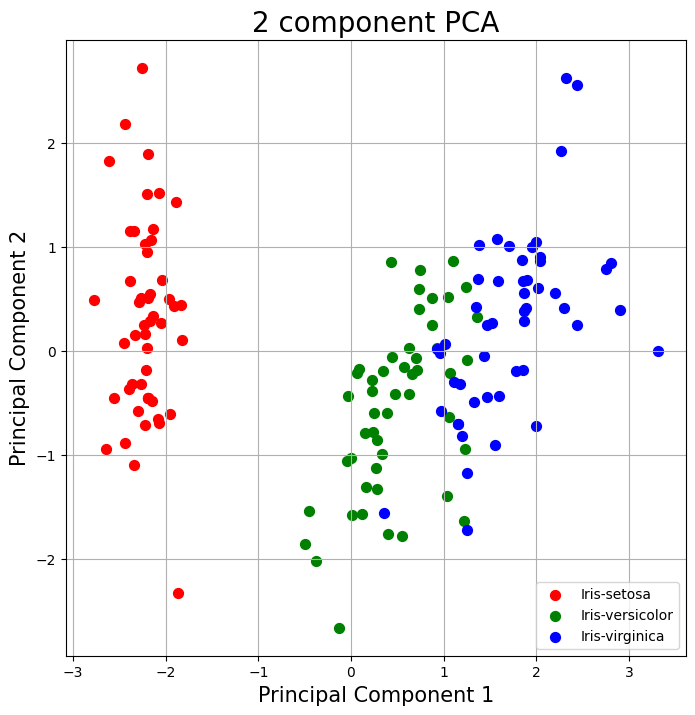

In [12]:
import matplotlib.pyplot as plt
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1)
ax.set_xlabel('Principal Component 1', fontsize = 15)
ax.set_ylabel('Principal Component 2', fontsize = 15)
ax.set_title('2 component PCA', fontsize = 20)

targets = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
colors = ['r', 'g', 'b']
for target, color in zip(targets,colors):
    indicesToKeep = finalDf['target'] == target
    ax.scatter(finalDf.loc[indicesToKeep, 'principal comp 1']
               , finalDf.loc[indicesToKeep, 'principal comp 2']
               , c = color
               , s = 50)
ax.legend(targets)
ax.grid()

In [13]:
pca.explained_variance_ratio_

array([0.72770452, 0.23030523])

I used the Iris dataset, which contains 150 flowers from three different species. Each flower has four features, including sepal and petal measurements. I applied PCA to reduce the four features to two principal components. The graph shows that Iris-setosa is clearly separated from the other two species, while Iris-versicolor and Iris-virginica overlap in some areas. This shows that PCA can simplify the data while still showing differences between flower species.

From the above result, the four dimensions reduced to 2 dimensions. By using the attribute explained_variance_ratio_, we see that the first component contains 73% of the variance and the second component contains 23% of the variance. Together, the two components contain 96% of the information.  In conclusion, this means that the original four dimensions can be reduced to two.